# Multi-Coin Statistical Analysis (Live, No Storage)

Six cryptos. Fetched fresh from Binance. Nothing written to disk.

**Symbols:** BTC, ETH, SOL, BNB, XRP, ZEC

**Data source:** Binance public `data-api.binance.vision` (no key, no geo-restriction)[citation:3]

**Sections:**

1. Fetch live candles (in memory)
2. Cumulative return
3. Return distributions
4. Volatility
5. Drawdown
6. Sharpe / Sortino / Calmar
7. Correlation matrix
8. Beta to BTC
9. Final ranking

## Setup

In [1]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (12, 4)

# data-api.binance.vision = public market data only, no auth, no geo-block[citation:3]
BASE = 'https://data-api.binance.vision'
SYMBOLS = ['BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'BNBUSDT', 'XRPUSDT', 'ZECUSDT']
DAYS = 730   # 2 years of daily candles
print('ready  (no storage)')

ready  (no storage)


## 1. Fetch live candles

Binance public market data endpoint. No API key, no database, data lives only in this notebook's memory.

In [2]:
def fetch_klines(symbol, interval='1d', limit=1000):
    r = requests.get(f'{BASE}/api/v3/klines',
                     params={'symbol': symbol, 'interval': interval,
                             'limit': limit}, timeout=15)
    r.raise_for_status()
    return r.json()


frames = {}
for sym in SYMBOLS:
    try:
        k = fetch_klines(sym, '1d', 1000)
        rows = []
        for x in k:
            rows.append({
                'date':   pd.to_datetime(int(x[0]), unit='ms', utc=True).tz_convert(None),
                'open':   float(x[1]),
                'high':   float(x[2]),
                'low':    float(x[3]),
                'close':  float(x[4]),
                'volume': float(x[5]),
            })
        d = pd.DataFrame(rows).set_index('date').sort_index()
        frames[sym] = d
        print(f'{sym:<10} {len(d):>4} candles  {d.index[0].date()} -> {d.index[-1].date()}')
    except Exception as e:
        print(f'{sym:<10} FAILED - {e}')
    time.sleep(0.15)

close = pd.DataFrame({sym: f['close'] for sym, f in frames.items()})
close = close.ffill().dropna()
print(f'\ncombined shape: {close.shape}')
print(f'date range: {close.index.min().date()} -> {close.index.max().date()}')

BTCUSDT    1000 candles  2024-01-29 -> 2026-10-24
ETHUSDT    1000 candles  2024-01-29 -> 2026-10-24
SOLUSDT    1000 candles  2024-01-29 -> 2026-10-24
BNBUSDT    1000 candles  2024-01-29 -> 2026-10-24
XRPUSDT    1000 candles  2024-01-29 -> 2026-10-24
ZECUSDT    1000 candles  2024-01-29 -> 2026-10-24

combined shape: (1000, 6)
date range: 2024-01-29 -> 2026-10-24


## 2. Cumulative return (log scale)

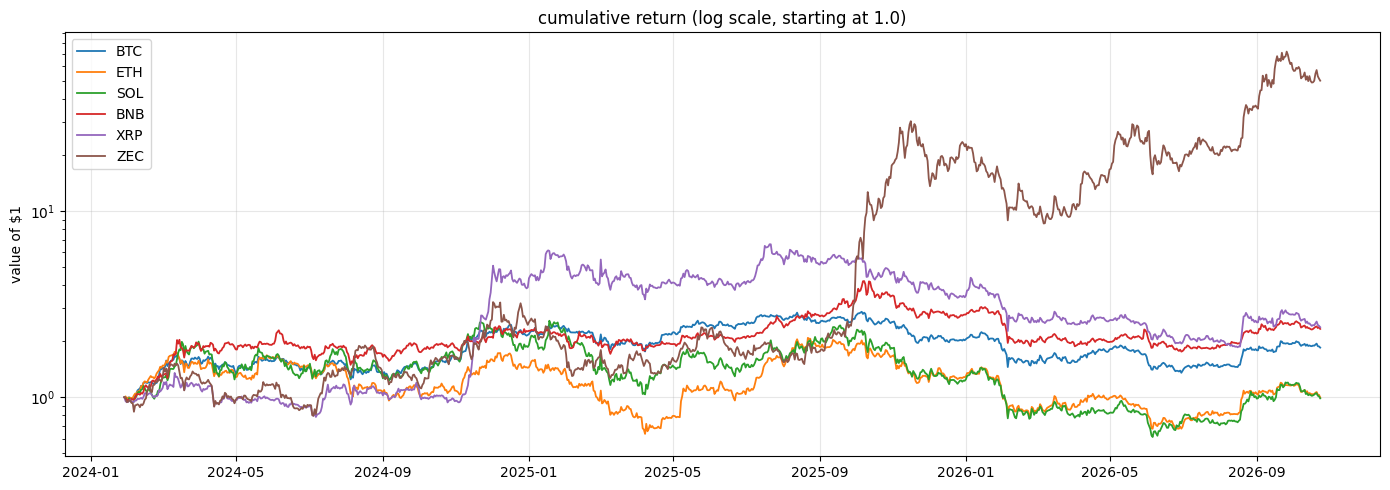


Final multiples over the window:
  ZECUSDT       50.19x
  XRPUSDT        2.38x
  BNBUSDT        2.33x
  BTCUSDT        1.85x
  ETHUSDT        1.00x
  SOLUSDT        0.99x


In [3]:
norm = close / close.iloc[0]

fig, ax = plt.subplots(figsize=(14, 5))
for sym in close.columns:
    ax.plot(norm.index, norm[sym], label=sym.replace('USDT',''), lw=1.3)
ax.set_yscale('log')
ax.set_title('cumulative return (log scale, starting at 1.0)')
ax.set_ylabel('value of $1')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

final = norm.iloc[-1].sort_values(ascending=False)
print('\nFinal multiples over the window:')
for sym, v in final.items():
    print(f'  {sym:<10} {v:>8.2f}x')

## 3. Daily return distributions

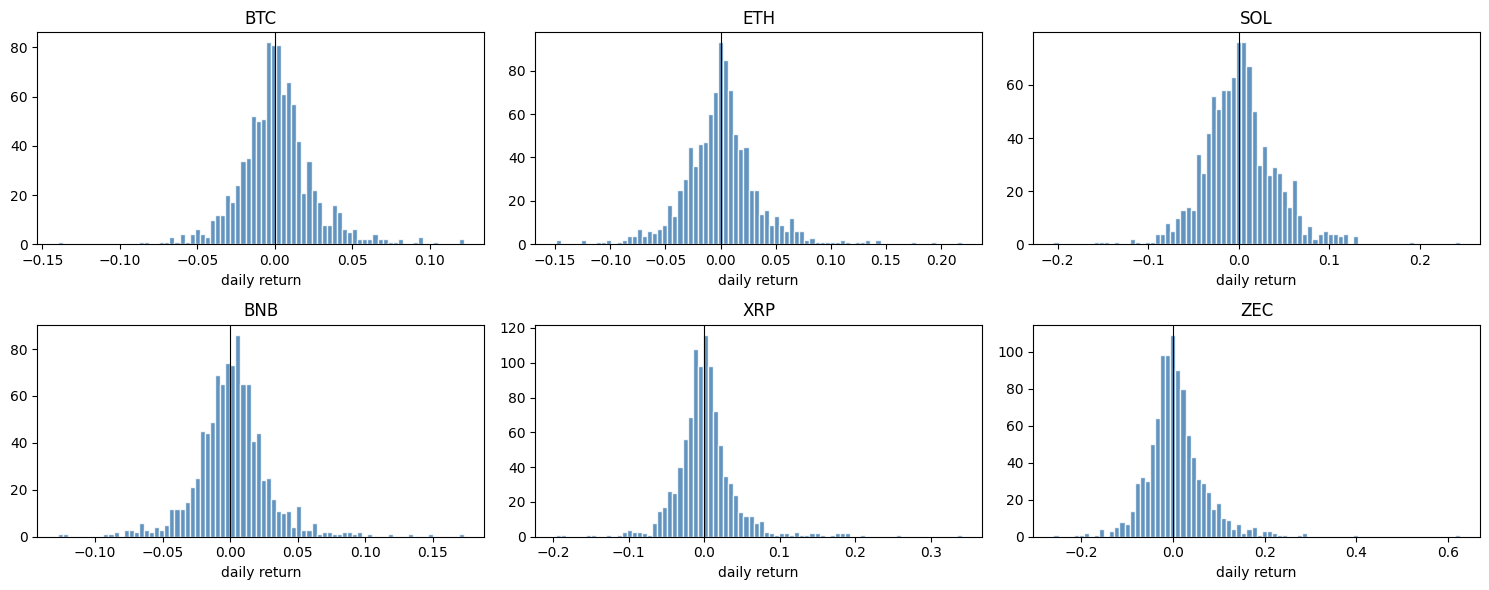

In [4]:
rets = close.pct_change().dropna()

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
axes = axes.flatten()
for i, sym in enumerate(close.columns):
    r = rets[sym].dropna()
    ax = axes[i]
    ax.hist(r, bins=80, color='steelblue', edgecolor='white', alpha=0.85)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(sym.replace('USDT',''))
    ax.set_xlabel('daily return')
for j in range(i+1, len(axes)):
    axes[j].axis('off')
plt.tight_layout(); plt.show()

## 4. Distribution statistics

In [5]:
dist = pd.DataFrame({
    'mean_%':   rets.mean() * 100,
    'median_%': rets.median() * 100,
    'std_%':    rets.std(ddof=0) * 100,
    'skew':     rets.skew(),
    'kurtosis': rets.kurtosis(),
    'min_%':    rets.min() * 100,
    'max_%':    rets.max() * 100,
})
print(dist.round(3).to_string())

         mean_%  median_%  std_%   skew  kurtosis   min_%   max_%
BTCUSDT   0.091     0.019  2.439  0.356     3.592 -14.017  12.193
ETHUSDT   0.062     0.085  3.540  0.613     4.636 -14.962  21.881
SOLUSDT   0.082     0.000  4.084  0.307     2.903 -20.452  24.398
BNBUSDT   0.122     0.113  2.741  0.452     4.765 -12.760  17.302
XRPUSDT   0.171    -0.096  4.167  1.394     9.819 -19.669  34.130
ZECUSDT   0.595    -0.043  6.534  1.560    10.759 -25.961  62.487


## 5. Annualized volatility

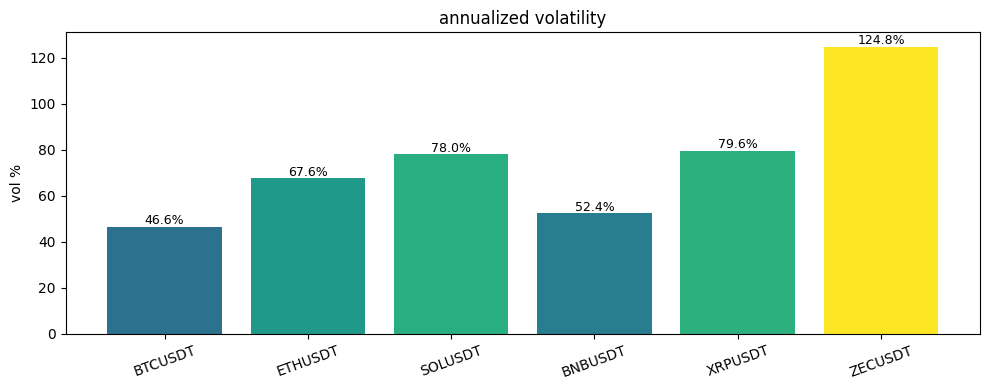

In [6]:
ann_vol = rets.std(ddof=0) * np.sqrt(365) * 100

fig, ax = plt.subplots(figsize=(10, 4))
colors = plt.cm.viridis(ann_vol / ann_vol.max())
bars = ax.bar(ann_vol.index, ann_vol.values, color=colors)
for b, v in zip(bars, ann_vol.values):
    ax.text(b.get_x() + b.get_width()/2, v + 1, f'{v:.1f}%',
            ha='center', fontsize=9)
ax.set_title('annualized volatility')
ax.set_ylabel('vol %')
plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

## 6. Drawdown from peak

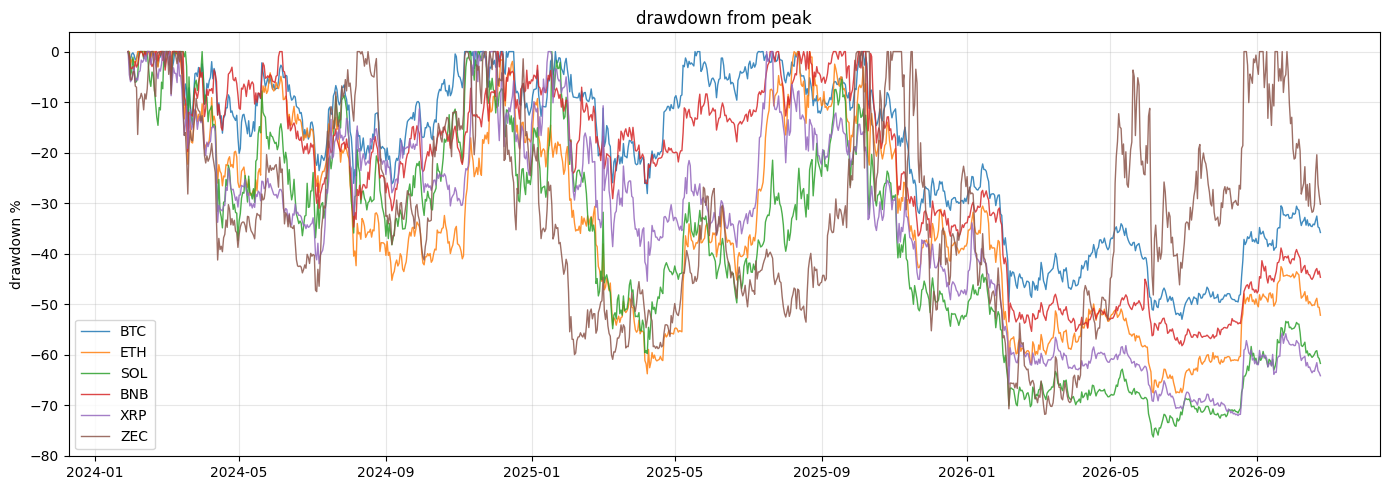


Max drawdowns:
  BTCUSDT     -52.97%
  ETHUSDT     -67.55%
  SOLUSDT     -76.26%
  BNBUSDT     -58.20%
  XRPUSDT     -72.01%
  ZECUSDT     -71.78%


In [7]:
def drawdown(series):
    cum = (1 + series.pct_change().fillna(0)).cumprod()
    peak = cum.cummax()
    return cum / peak - 1

dd = pd.DataFrame({sym: drawdown(close[sym]) for sym in close.columns})

fig, ax = plt.subplots(figsize=(14, 5))
for sym in dd.columns:
    ax.plot(dd.index, dd[sym] * 100, label=sym.replace('USDT',''), lw=1.0, alpha=0.85)
ax.set_title('drawdown from peak')
ax.set_ylabel('drawdown %')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print('\nMax drawdowns:')
for sym in dd.columns:
    print(f'  {sym:<10} {dd[sym].min()*100:>7.2f}%')

## 7. Risk-adjusted metrics

In [8]:
def risk_metrics(series):
    r = series.pct_change().dropna()
    total = (1 + r).prod() - 1
    years = len(r) / 365
    ann_ret = (1 + total) ** (1/years) - 1 if years > 0 else 0
    vol = r.std(ddof=0) * np.sqrt(365)
    downside = r[r < 0].std(ddof=0) * np.sqrt(365)
    dd = (1 + r).cumprod() / (1 + r).cumprod().cummax() - 1
    return {
        'total_ret_%': total * 100,
        'ann_ret_%':   ann_ret * 100,
        'ann_vol_%':   vol * 100,
        'sharpe':      ann_ret / vol if vol > 0 else 0,
        'sortino':     ann_ret / downside if downside > 0 else 0,
        'calmar':      ann_ret / abs(dd.min()) if dd.min() < 0 else 0,
        'max_dd_%':    dd.min() * 100,
    }

metrics = pd.DataFrame({sym: risk_metrics(close[sym]) for sym in close.columns}).T
print(metrics.round(2).to_string())

         total_ret_%  ann_ret_%  ann_vol_%  sharpe  sortino  calmar  max_dd_%
BTCUSDT        84.85      25.17      46.60    0.54     0.83    0.48    -52.97
ETHUSDT        -0.26      -0.09      67.63   -0.00    -0.00   -0.00    -67.55
SOLUSDT        -1.31      -0.48      78.03   -0.01    -0.01   -0.01    -76.26
BNBUSDT       132.92      36.20      52.36    0.69     1.03    0.62    -58.20
XRPUSDT       137.97      37.27      79.60    0.47     0.78    0.52    -72.01
ZECUSDT      4918.96     318.16     124.83    2.55     4.71    4.43    -71.78


## 8. Correlation matrix

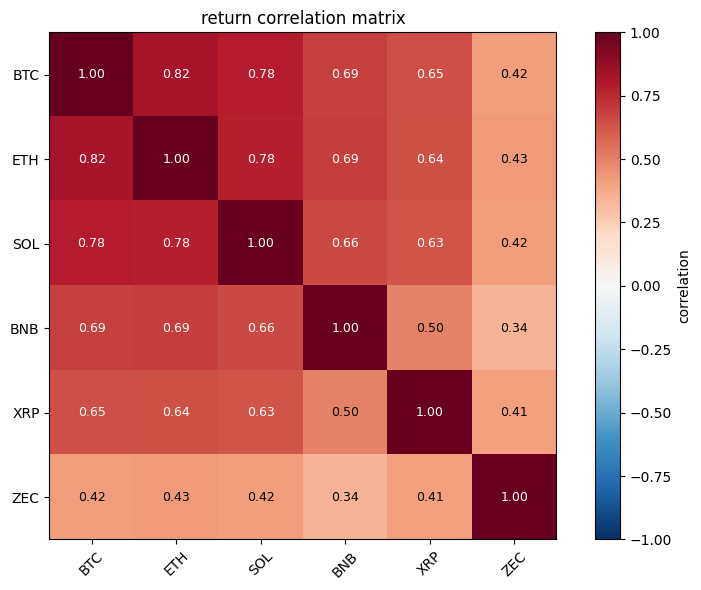


Correlation to BTC:
ETHUSDT    0.824
SOLUSDT    0.783
BNBUSDT    0.687
XRPUSDT    0.647
ZECUSDT    0.421


In [9]:
corr = rets.corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels([s.replace('USDT','') for s in corr.columns], rotation=45)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels([s.replace('USDT','') for s in corr.columns])
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}',
                ha='center', va='center', fontsize=9,
                color='white' if abs(corr.iloc[i,j]) > 0.6 else 'black')
plt.colorbar(im, ax=ax, label='correlation')
ax.set_title('return correlation matrix')
plt.tight_layout(); plt.show()

print('\nCorrelation to BTC:')
print(corr['BTCUSDT'].drop('BTCUSDT').sort_values(ascending=False).round(3).to_string())

## 9. Beta to BTC

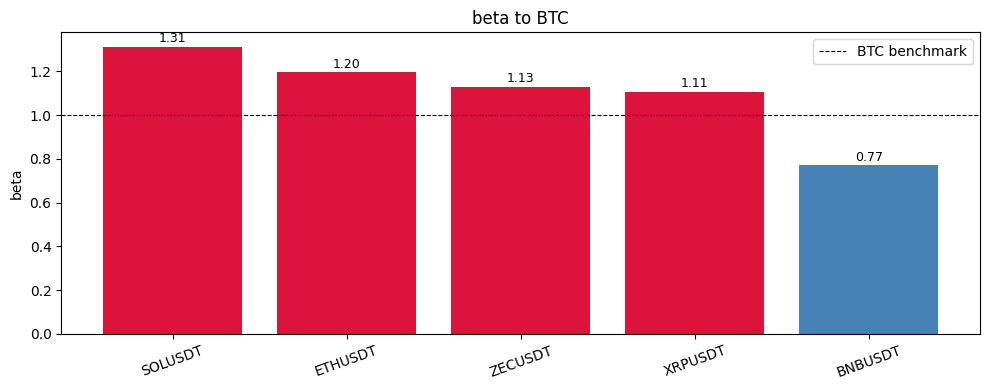

In [10]:
btc = rets['BTCUSDT']

betas = {}
for sym in rets.columns:
    if sym == 'BTCUSDT': continue
    y = rets[sym]
    x = btc
    cov = np.cov(x, y)[0, 1]
    var = np.var(x, ddof=0)
    betas[sym] = cov / var if var > 0 else 0

beta_series = pd.Series(betas).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
colors = ['crimson' if v > 1 else 'steelblue' for v in beta_series.values]
bars = ax.bar(beta_series.index, beta_series.values, color=colors)
ax.axhline(1.0, color='black', lw=0.8, ls='--', label='BTC benchmark')
for b, v in zip(bars, beta_series.values):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.2f}',
            ha='center', fontsize=9)
ax.set_title('beta to BTC')
ax.set_ylabel('beta')
ax.legend()
plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

## 10. Final ranking

In [11]:
rank = pd.DataFrame({
    'total_ret_%': metrics['total_ret_%'],
    'ann_ret_%':   metrics['ann_ret_%'],
    'ann_vol_%':   metrics['ann_vol_%'],
    'sharpe':      metrics['sharpe'],
    'sortino':     metrics['sortino'],
    'calmar':      metrics['calmar'],
    'max_dd_%':    metrics['max_dd_%'],
})
rank = rank.round(2).sort_values('sharpe', ascending=False)
print(rank.to_string())

print()
print('=' * 60)
print('BEST COIN BY METRIC')
print('=' * 60)
print(f"  Highest total return  : {metrics['total_ret_%'].idxmax()}")
print(f"  Best Sharpe           : {metrics['sharpe'].idxmax()}")
print(f"  Best Sortino          : {metrics['sortino'].idxmax()}")
print(f"  Best Calmar           : {metrics['calmar'].idxmax()}")
print(f"  Lowest volatility     : {metrics['ann_vol_%'].idxmin()}")
print(f"  Smallest drawdown     : {metrics['max_dd_%'].idxmax()}")

         total_ret_%  ann_ret_%  ann_vol_%  sharpe  sortino  calmar  max_dd_%
ZECUSDT      4918.96     318.16     124.83    2.55     4.71    4.43    -71.78
BNBUSDT       132.92      36.20      52.36    0.69     1.03    0.62    -58.20
BTCUSDT        84.85      25.17      46.60    0.54     0.83    0.48    -52.97
XRPUSDT       137.97      37.27      79.60    0.47     0.78    0.52    -72.01
ETHUSDT        -0.26      -0.09      67.63   -0.00    -0.00   -0.00    -67.55
SOLUSDT        -1.31      -0.48      78.03   -0.01    -0.01   -0.01    -76.26

BEST COIN BY METRIC
  Highest total return  : ZECUSDT
  Best Sharpe           : ZECUSDT
  Best Sortino          : ZECUSDT
  Best Calmar           : ZECUSDT
  Lowest volatility     : BTCUSDT
  Smallest drawdown     : BTCUSDT


## Notes

- **No data is saved.** Everything exists only in this notebook's RAM.
- Re-running fetches fresh data. Nothing persists between runs.
- Data source is `data-api.binance.vision` — public, no key, no geo-block[citation:3].
- 2 years of daily candles per symbol. Change `DAYS` if you want more (max 1000 candles per request, ~2.7 years).
- ZEC may have gaps due to its 2023 delisting/relisting. `ffill()` handles chart continuity but return stats during gaps are zero.